# Three-Client Federated Learning for Cervical Cell Images

**MobileNetV3-Small | Centralized baseline | FedAvg | FedProx | FedAdam | IID vs non-IID clients**

This notebook compares one centralized model with three federated algorithms, holding the model architecture and client count fixed. It uses exactly **three simulated clients** and evaluates IID (similar client class distributions) and non-IID (heterogeneous client class distributions) partitions.

> **Scope:** clients are data partitions simulated in one Python process—not separate hospitals. This is an experimental classification project, not a clinically validated diagnostic system. Federated learning alone is not a formal privacy guarantee.

## Before running
- Set `DATASET_ROOT` below to the directory whose immediate child folders are the SIPaKMeD classes.
- The exploratory default uses one seed. For final results use at least three seeds, e.g. `[42, 123, 2025]`.
- `USE_PRETRAINED=True` downloads ImageNet weights unless cached; internet access may be required.
- The notebook uses image-level stratified splits. If patient/slide identifiers are available, use a group-aware split instead.


## Protocol

- Stratified 70% / 15% / 15% train, validation, test split; the same split is reused across methods for each seed.
- Three clients are constructed from training data only. IID and Dirichlet non-IID partitions are each generated once per seed and reused across FL methods.
- Every method starts from the same ImageNet-pretrained MobileNetV3-Small state, including the same initialized five-class head.
- Default budget: 10 rounds × 1 local epoch; centralized training gets 10 full-data epochs. Keep the budget fixed for comparisons.
- Validation macro-F1 selects the checkpoint. The held-out test split is evaluated only after training.
- FedAvg: sample-count-weighted model aggregation. FedProx: adds `mu/2 * ||local-global||²` to local loss. FedAdam: server-side Adam-style update of the weighted mean client parameter delta; buffers are averaged.
- Report accuracy, macro/weighted F1, per-class precision/recall/F1, confusion matrices, runtime, and approximate communication volume.


In [1]:
# If running outside Kaggle/Colab, install first if needed:
# %pip install torch torchvision scikit-learn pandas matplotlib pillow
import os, copy, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

DATASET_ROOT = Path(os.environ.get("SIPAKMED_ROOT", "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"))
NUM_CLIENTS = 3
RUN_SEEDS = [42, 123, 2025]                 # final report: [42, 123, 2025]
NUM_ROUNDS = 10                  # smoke test: 2
LOCAL_EPOCHS = 1                 # centralized epochs = rounds * local epochs
BATCH_SIZE = 32
NUM_WORKERS = 2                 # robust in notebooks; increase if suitable
USE_PRETRAINED = True
LOCAL_LR = 1e-4
WEIGHT_DECAY = 1e-4
DIRICHLET_ALPHA = 0.5
FEDPROX_MU = 0.01                # select/tune using validation only
FEDADAM_SERVER_LR = 0.01
FEDADAM_BETA1, FEDADAM_BETA2, FEDADAM_TAU = 0.9, 0.99, 1e-3
OUTPUT_DIR = Path("federated_mobilenet_results")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| Dataset:", DATASET_ROOT, "| Outputs:", OUTPUT_DIR.resolve())


Device: cuda | Dataset: /kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed | Outputs: /kaggle/working/federated_mobilenet_results


## 1. Dataset, class order, and separate transforms

The ImageFolder class order is recorded and reused. Random flips are applied only to training images; validation and test images receive deterministic resizing and normalization.


In [2]:
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATASET_ROOT}. Set DATASET_ROOT or SIPAKMED_ROOT to the folder containing the class subfolders.")
index_dataset = datasets.ImageFolder(root=str(DATASET_ROOT))
CLASS_NAMES = index_dataset.classes
SAMPLES = index_dataset.samples
LABELS = np.asarray([y for _, y in SAMPLES], dtype=np.int64)
NUM_CLASSES = len(CLASS_NAMES)
print("Class order:", list(enumerate(CLASS_NAMES)))
print("Total images:", len(SAMPLES))
display(pd.Series([CLASS_NAMES[y] for y in LABELS]).value_counts().reindex(CLASS_NAMES))
if NUM_CLASSES != 5:
    warnings.warn(f"Expected five folders, found {NUM_CLASSES}: {CLASS_NAMES}")

TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])])
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])])

class CervicalCellDataset(Dataset):
    def __init__(self, samples, indices, transform):
        self.samples, self.indices, self.transform = samples, np.asarray(indices), transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        path, label = self.samples[int(self.indices[i])]
        with Image.open(path) as im: image = im.convert("RGB")
        return self.transform(image), int(label)


Class order: [(0, 'im_Dyskeratotic'), (1, 'im_Koilocytotic'), (2, 'im_Metaplastic'), (3, 'im_Parabasal'), (4, 'im_Superficial-Intermediate')]
Total images: 5015


im_Dyskeratotic                1036
im_Koilocytotic                1063
im_Metaplastic                 1064
im_Parabasal                    895
im_Superficial-Intermediate     957
Name: count, dtype: int64

## 2. Stratified split and three-client IID/non-IID partitions

For non-IID, class-specific samples are divided among three clients using a Dirichlet distribution (`alpha=0.5`). Lower alpha generally produces stronger label skew. The code verifies that only training indices are partitioned among clients.


In [3]:
def make_split(labels, seed):
    idx = np.arange(len(labels))
    train_idx, temp_idx = train_test_split(idx, test_size=.30, random_state=seed, stratify=labels)
    val_idx, test_idx = train_test_split(temp_idx, test_size=.50, random_state=seed+1, stratify=labels[temp_idx])
    return np.asarray(train_idx), np.asarray(val_idx), np.asarray(test_idx)

def partition_iid(train_idx, labels, n_clients, seed):
    rng = np.random.default_rng(seed)
    parts = [[] for _ in range(n_clients)]
    for cls in np.unique(labels[train_idx]):
        ix = train_idx[labels[train_idx] == cls].copy(); rng.shuffle(ix)
        for c, chunk in enumerate(np.array_split(ix, n_clients)): parts[c].extend(chunk.tolist())
    return [np.asarray(sorted(p), dtype=np.int64) for p in parts]

def partition_dirichlet(train_idx, labels, n_clients, alpha, seed, max_tries=100):
    rng = np.random.default_rng(seed)
    for _ in range(max_tries):
        parts = [[] for _ in range(n_clients)]
        for cls in np.unique(labels[train_idx]):
            ix = train_idx[labels[train_idx] == cls].copy(); rng.shuffle(ix)
            proportions = rng.dirichlet(np.repeat(alpha, n_clients))
            cuts = (np.cumsum(proportions)[:-1] * len(ix)).astype(int)
            for c, chunk in enumerate(np.split(ix, cuts)): parts[c].extend(chunk.tolist())
        if all(len(p) for p in parts): return [np.asarray(sorted(p), dtype=np.int64) for p in parts]
    raise RuntimeError("Failed to create non-empty clients; increase Dirichlet alpha.")

def show_client_distribution(parts, labels, title):
    rows=[]
    for c, ix in enumerate(parts):
        counts=np.bincount(labels[ix], minlength=len(CLASS_NAMES))
        rows.append({"client":f"Client {c+1}", "n_images":len(ix), **{n:int(counts[i]) for i,n in enumerate(CLASS_NAMES)}})
    print(title); display(pd.DataFrame(rows))

_preview_train, _preview_val, _preview_test = make_split(LABELS, RUN_SEEDS[0])
_preview_iid = partition_iid(_preview_train, LABELS, NUM_CLIENTS, RUN_SEEDS[0]+10)
_preview_non_iid = partition_dirichlet(_preview_train, LABELS, NUM_CLIENTS, DIRICHLET_ALPHA, RUN_SEEDS[0]+20)
show_client_distribution(_preview_iid, LABELS, "IID client distribution")
show_client_distribution(_preview_non_iid, LABELS, f"Non-IID distribution (Dirichlet alpha={DIRICHLET_ALPHA})")


IID client distribution


,client,n_images,im_Dyskeratotic,im_Koilocytotic,im_Metaplastic,im_Parabasal,im_Superficial-Intermediate
0,Client 1,1172,242,248,249,209,224
1,Client 2,1170,242,248,248,209,223
2,Client 3,1168,241,248,248,208,223


Non-IID distribution (Dirichlet alpha=0.5)


,client,n_images,im_Dyskeratotic,im_Koilocytotic,im_Metaplastic,im_Parabasal,im_Superficial-Intermediate
0,Client 1,718,205,160,13,0,340
1,Client 2,1581,340,526,331,77,307
2,Client 3,1211,180,58,401,549,23


## 3. Model initialization and data loaders

The same initial model state—including the classifier head—is cloned for the centralized baseline and all FL methods for a given seed. If pretrained weights cannot be fetched, set `USE_PRETRAINED=False` consistently and report it.


In [4]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def build_model(pretrained=False):
    weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
    model = models.mobilenet_v3_small(weights=weights)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, NUM_CLASSES)
    return model

def cpu_state(model): return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
def make_initial_state(seed):
    set_seed(seed); return cpu_state(build_model(pretrained=USE_PRETRAINED))

def make_loader(indices, train, seed, shuffle=None):
    ds = CervicalCellDataset(SAMPLES, indices, TRAIN_TRANSFORM if train else EVAL_TRANSFORM)
    if shuffle is None: shuffle=train
    gen=torch.Generator(); gen.manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type=="cuda"), generator=gen, drop_last=False)


## 4. Evaluation and algorithm implementations

All local training uses the same AdamW optimizer and cross-entropy loss. FedProx changes the local objective; FedAdam changes the server parameter update. FedAvg and FedProx use sample-count-weighted averaging.


In [5]:
def evaluate_model(model, loader):
    model.eval(); criterion=nn.CrossEntropyLoss(); total_loss=0.; n=0; ys=[]; ps=[]
    with torch.no_grad():
        for x,y in loader:
            x=x.to(DEVICE, non_blocking=True); y=y.to(DEVICE, non_blocking=True)
            logits=model(x); loss=criterion(logits,y); pred=logits.argmax(1)
            total_loss += loss.item()*y.size(0); n += y.size(0)
            ys.extend(y.cpu().tolist()); ps.extend(pred.cpu().tolist())
    prec,rec,f1,support=precision_recall_fscore_support(ys,ps,labels=list(range(NUM_CLASSES)),zero_division=0)
    weighted=precision_recall_fscore_support(ys,ps,average="weighted",zero_division=0)[2]
    return {"loss":total_loss/max(n,1), "accuracy":accuracy_score(ys,ps),
            "macro_f1":float(np.mean(f1)), "weighted_f1":weighted,
            "y_true":np.asarray(ys), "y_pred":np.asarray(ps),
            "precision_per_class":prec,"recall_per_class":rec,"f1_per_class":f1,"support_per_class":support}

def train_client(global_state, loader, seed, algorithm, mu=0.):
    set_seed(seed); model=build_model(pretrained=False); model.load_state_dict(global_state); model.to(DEVICE)
    optimizer=optim.AdamW(model.parameters(),lr=LOCAL_LR,weight_decay=WEIGHT_DECAY); criterion=nn.CrossEntropyLoss()
    reference=[p.detach().clone() for p in model.parameters()] if algorithm=="fedprox" else None
    for _ in range(LOCAL_EPOCHS):
        model.train()
        for x,y in loader:
            x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True); loss=criterion(model(x),y)
            if algorithm=="fedprox":
                prox=sum(torch.sum((p-r)**2) for p,r in zip(model.parameters(),reference))
                loss=loss+(mu/2.)*prox
            loss.backward(); optimizer.step()
    state=cpu_state(model); del model,optimizer
    if DEVICE.type=="cuda": torch.cuda.empty_cache()
    return state

def weighted_average(states, weights):
    out={}
    for key in states[0]:
        vals=[s[key] for s in states]
        if torch.is_floating_point(vals[0]):
            acc=torch.zeros_like(vals[0],dtype=torch.float32)
            for w,v in zip(weights,vals): acc += float(w)*v.float()
            out[key]=acc.to(vals[0].dtype)
        else: out[key]=torch.stack(vals).max(0).values
    return out

def fedadam_step(global_state, local_states, weights, parameter_keys, m, v, step):
    out={}
    for key in global_state:
        vals=[s[key] for s in local_states]
        if key in parameter_keys:
            delta=torch.zeros_like(global_state[key],dtype=torch.float32)
            for w,val in zip(weights,vals): delta += float(w)*(val.float()-global_state[key].float())
            m[key]=FEDADAM_BETA1*m[key]+(1-FEDADAM_BETA1)*delta
            v[key]=FEDADAM_BETA2*v[key]+(1-FEDADAM_BETA2)*(delta**2)
            mh=m[key]/(1-FEDADAM_BETA1**step); vh=v[key]/(1-FEDADAM_BETA2**step)
            out[key]=(global_state[key].float()+FEDADAM_SERVER_LR*mh/(torch.sqrt(vh)+FEDADAM_TAU)).to(global_state[key].dtype)
        elif torch.is_floating_point(global_state[key]):
            acc=torch.zeros_like(global_state[key],dtype=torch.float32)
            for w,val in zip(weights,vals): acc += float(w)*val.float()
            out[key]=acc.to(global_state[key].dtype)
        else: out[key]=torch.stack(vals).max(0).values
    return out,m,v


## 5. Centralized and federated trainers

The centralized epoch count equals `NUM_ROUNDS * LOCAL_EPOCHS`, matching the number of full-training-set passes represented by the FL rounds. Each FL client starts every round from the current global state. The best validation macro-F1 checkpoint is saved; test data is not used here.


In [6]:
def run_centralized(seed, initial, train_idx, val_idx):
    set_seed(seed); train_loader=make_loader(train_idx,True,seed+100); val_loader=make_loader(val_idx,False,seed+101,False)
    model=build_model(False); model.load_state_dict(initial); model.to(DEVICE)
    opt=optim.AdamW(model.parameters(),lr=LOCAL_LR,weight_decay=WEIGHT_DECAY); crit=nn.CrossEntropyLoss()
    best=-1.; best_state=cpu_state(model); history=[]; epochs=NUM_ROUNDS*LOCAL_EPOCHS; start=time.perf_counter()
    for epoch in range(1,epochs+1):
        model.train()
        for x,y in train_loader:
            x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True); loss=crit(model(x),y); loss.backward(); opt.step()
        met=evaluate_model(model,val_loader)
        history.append({"epoch":epoch,"val_loss":met["loss"],"val_accuracy":met["accuracy"],"val_macro_f1":met["macro_f1"]})
        if met["macro_f1"]>best: best=met["macro_f1"]; best_state=cpu_state(model)
        print(f"Central {epoch}/{epochs}: val acc={met['accuracy']:.4f}; macro-F1={met['macro_f1']:.4f}")
    elapsed=time.perf_counter()-start; path=OUTPUT_DIR/f"central_seed{seed}.pt"
    torch.save({"state_dict":best_state,"class_names":CLASS_NAMES,"seed":seed,"best_val_macro_f1":best,"model":"MobileNetV3-Small"},path)
    del model,opt
    return history,path,elapsed

def run_federated(seed, initial, val_idx, parts, distribution, algorithm):
    loaders=[make_loader(ix,True,seed+200+c) for c,ix in enumerate(parts)]
    val_loader=make_loader(val_idx,False,seed+300,False)
    global_state={k:v.clone() for k,v in initial.items()}
    param_keys=set(dict(build_model(False).named_parameters()).keys())
    m={k:torch.zeros_like(global_state[k],dtype=torch.float32) for k in param_keys}
    v={k:torch.zeros_like(global_state[k],dtype=torch.float32) for k in param_keys}
    sizes=np.asarray([len(p) for p in parts],dtype=float); weights=sizes/sizes.sum()
    best=-1.; best_state={k:x.clone() for k,x in global_state.items()}; history=[]; start=time.perf_counter()
    for rnd in range(1,NUM_ROUNDS+1):
        local=[train_client(global_state,loader,seed+rnd*1000+c,algorithm,FEDPROX_MU) for c,loader in enumerate(loaders)]
        if algorithm in ("fedavg","fedprox"): global_state=weighted_average(local,weights)
        elif algorithm=="fedadam": global_state,m,v=fedadam_step(global_state,local,weights,param_keys,m,v,rnd)
        else: raise ValueError(algorithm)
        model=build_model(False); model.load_state_dict(global_state); model.to(DEVICE)
        met=evaluate_model(model,val_loader); del model
        history.append({"round":rnd,"val_loss":met["loss"],"val_accuracy":met["accuracy"],"val_macro_f1":met["macro_f1"]})
        if met["macro_f1"]>best: best=met["macro_f1"]; best_state={k:x.clone() for k,x in global_state.items()}
        print(f"{distribution} {algorithm} round {rnd}/{NUM_ROUNDS}: val acc={met['accuracy']:.4f}; macro-F1={met['macro_f1']:.4f}")
    elapsed=time.perf_counter()-start; path=OUTPUT_DIR/f"{algorithm}_{distribution}_seed{seed}.pt"
    torch.save({"state_dict":best_state,"class_names":CLASS_NAMES,"seed":seed,"algorithm":algorithm,
                "distribution":distribution,"best_val_macro_f1":best,"num_rounds":NUM_ROUNDS,
                "local_epochs":LOCAL_EPOCHS,"client_sizes":sizes.astype(int).tolist(),
                "dirichlet_alpha":DIRICHLET_ALPHA if distribution=="non_iid" else None,
                "model":"MobileNetV3-Small"},path)
    return history,path,elapsed


## 6. Run the experiment matrix

Per seed, the notebook trains one centralized model and six FL models (three algorithms × two client distributions). The client count remains exactly three. Start with one seed to verify everything, then use three or more seeds for the report.


In [7]:
all_histories=[]; run_records=[]; artifacts=[]
for seed in RUN_SEEDS:
    print("\n"+"="*70+f"\nSEED {seed}\n"+"="*70)
    train_idx,val_idx,test_idx=make_split(LABELS,seed)
    iid=partition_iid(train_idx,LABELS,NUM_CLIENTS,seed+10)
    noniid=partition_dirichlet(train_idx,LABELS,NUM_CLIENTS,DIRICHLET_ALPHA,seed+20)
    initial=make_initial_state(seed)
    hist,path,elapsed=run_centralized(seed,initial,train_idx,val_idx)
    all_histories += [{"seed":seed,"method":"centralized","distribution":"centralized",**r} for r in hist]
    run_records.append({"seed":seed,"method":"centralized","distribution":"centralized","runtime_seconds":elapsed,"checkpoint":str(path)})
    artifacts.append({"seed":seed,"method":"centralized","distribution":"centralized","checkpoint":path,"test_indices":test_idx})
    for dist,parts in [("iid",iid),("non_iid",noniid)]:
        for algo in ["fedavg","fedprox","fedadam"]:
            hist,path,elapsed=run_federated(seed,initial,val_idx,parts,dist,algo)
            all_histories += [{"seed":seed,"method":algo,"distribution":dist,**r} for r in hist]
            run_records.append({"seed":seed,"method":algo,"distribution":dist,"runtime_seconds":elapsed,"checkpoint":str(path)})
            artifacts.append({"seed":seed,"method":algo,"distribution":dist,"checkpoint":path,"test_indices":test_idx})

history_df=pd.DataFrame(all_histories); runs_df=pd.DataFrame(run_records)
history_df.to_csv(OUTPUT_DIR/"validation_history.csv",index=False)
runs_df.to_csv(OUTPUT_DIR/"run_metadata.csv",index=False)
print("Completed configurations:",len(runs_df)); display(runs_df[["seed","method","distribution","runtime_seconds"]])



SEED 42
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 96.5MB/s]


Central 1/10: val acc=0.7660; macro-F1=0.7627
Central 2/10: val acc=0.8923; macro-F1=0.8934
Central 3/10: val acc=0.9269; macro-F1=0.9280
Central 4/10: val acc=0.9309; macro-F1=0.9325
Central 5/10: val acc=0.9402; macro-F1=0.9417
Central 6/10: val acc=0.9508; macro-F1=0.9521
Central 7/10: val acc=0.9495; macro-F1=0.9508
Central 8/10: val acc=0.9508; macro-F1=0.9519
Central 9/10: val acc=0.9548; macro-F1=0.9558
Central 10/10: val acc=0.9601; macro-F1=0.9610
iid fedavg round 1/10: val acc=0.4787; macro-F1=0.4718
iid fedavg round 2/10: val acc=0.6503; macro-F1=0.6461
iid fedavg round 3/10: val acc=0.7633; macro-F1=0.7626
iid fedavg round 4/10: val acc=0.8178; macro-F1=0.8195
iid fedavg round 5/10: val acc=0.8564; macro-F1=0.8569
iid fedavg round 6/10: val acc=0.8883; macro-F1=0.8901
iid fedavg round 7/10: val acc=0.8949; macro-F1=0.8959
iid fedavg round 8/10: val acc=0.9176; macro-F1=0.9190
iid fedavg round 9/10: val acc=0.9189; macro-F1=0.9206
iid fedavg round 10/10: val acc=0.9255; macr

,seed,method,distribution,runtime_seconds
0,42,centralized,centralized,556.643091
1,42,fedavg,iid,267.608737
2,42,fedprox,iid,267.896448
3,42,fedadam,iid,271.342998
4,42,fedavg,non_iid,265.080419
5,42,fedprox,non_iid,269.051936
6,42,fedadam,non_iid,278.148613
7,123,centralized,centralized,268.388886
8,123,fedavg,iid,271.715401
9,123,fedprox,iid,270.502830


## 7. Final held-out test evaluation

The selected checkpoints are evaluated on the test split after all training is complete. Do not tune hyperparameters based on these test results. If you revise the experiment after inspecting test outcomes, use a fresh holdout if possible.


In [8]:
def load_ckpt(path):
    try: return torch.load(path,map_location="cpu",weights_only=False)
    except TypeError: return torch.load(path,map_location="cpu")

def evaluate_checkpoint(path,test_idx):
    ckpt=load_ckpt(path); model=build_model(False); model.load_state_dict(ckpt["state_dict"]); model.to(DEVICE)
    met=evaluate_model(model,make_loader(test_idx,False,999,False)); del model
    return ckpt,met

test_rows=[]; class_rows=[]; confusion_artifacts={}
for art in artifacts:
    ckpt,met=evaluate_checkpoint(art["checkpoint"],art["test_indices"])
    test_rows.append({"seed":art["seed"],"method":art["method"],"distribution":art["distribution"],
                      "accuracy":met["accuracy"],"macro_f1":met["macro_f1"],"weighted_f1":met["weighted_f1"],
                      "test_loss":met["loss"],"best_val_macro_f1":ckpt["best_val_macro_f1"]})
    confusion_artifacts[(art["seed"],art["method"],art["distribution"])]=(met["y_true"],met["y_pred"])
    for i,name in enumerate(CLASS_NAMES):
        class_rows.append({"seed":art["seed"],"method":art["method"],"distribution":art["distribution"],
                           "class":name,"precision":met["precision_per_class"][i],"recall":met["recall_per_class"][i],
                           "f1":met["f1_per_class"][i],"support":met["support_per_class"][i]})
test_df=pd.DataFrame(test_rows); per_class_df=pd.DataFrame(class_rows)
test_df.to_csv(OUTPUT_DIR/"test_metrics_by_seed.csv",index=False)
per_class_df.to_csv(OUTPUT_DIR/"per_class_metrics_by_seed.csv",index=False)
display(test_df.sort_values(["distribution","method","seed"]))


,seed,method,distribution,accuracy,macro_f1,weighted_f1,test_loss,best_val_macro_f1
0,42,centralized,centralized,0.952191,0.953780,0.951737,0.164253,0.960950
7,123,centralized,centralized,0.945551,0.948186,0.945967,0.166963,0.964982
14,2025,centralized,centralized,0.952191,0.953419,0.952134,0.116288,0.969069
3,42,fedadam,iid,0.922975,0.923995,0.921024,0.353296,0.930763
10,123,fedadam,iid,0.940239,0.941653,0.939671,0.271293,0.937248
17,2025,fedadam,iid,0.922975,0.923749,0.922074,0.359950,0.930598
1,42,fedavg,iid,0.937583,0.939309,0.936841,0.206627,0.927099
8,123,fedavg,iid,0.930943,0.933692,0.931297,0.182430,0.949411
15,2025,fedavg,iid,0.930943,0.932578,0.930354,0.189132,0.948167
2,42,fedprox,iid,0.936255,0.937910,0.935631,0.205042,0.929607


## 8. Summary metrics and learning curves

The summary reports mean and standard deviation across seeds. With the default single seed, standard deviation is unavailable; use multiple seeds before claiming robustness.


,method,distribution,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std
0,centralized,centralized,3,0.949978,0.003834,0.951795,0.003131,0.949946,0.003452
1,fedadam,iid,3,0.928730,0.009968,0.929799,0.010267,0.927590,0.010476
2,fedadam,non_iid,3,0.918548,0.013102,0.919758,0.013214,0.917633,0.013690
3,fedavg,iid,3,0.933156,0.003834,0.935193,0.003608,0.932831,0.003505
4,fedavg,non_iid,3,0.931828,0.006684,0.933764,0.006244,0.931464,0.006606
5,fedprox,iid,3,0.936698,0.003342,0.938628,0.003022,0.936441,0.003182
6,fedprox,non_iid,3,0.934042,0.006815,0.935892,0.006390,0.933621,0.006746


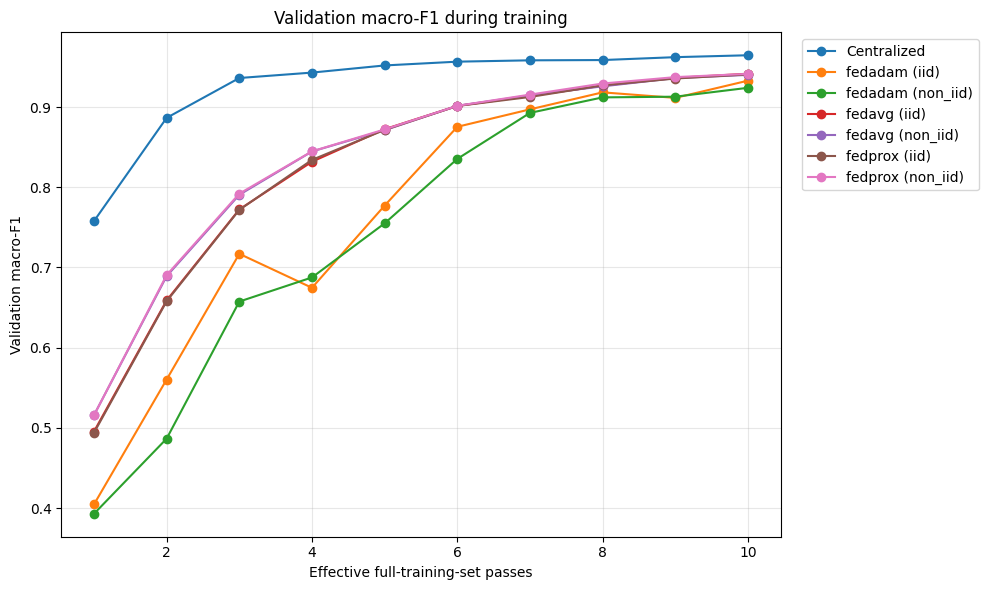

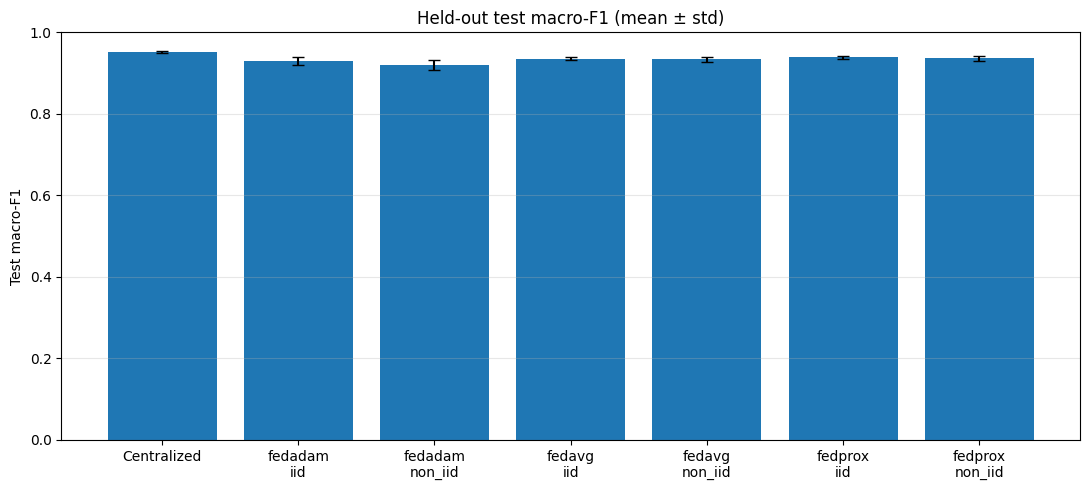

In [9]:
summary=test_df.groupby(["method","distribution"]).agg(
    n_runs=("accuracy","count"),accuracy_mean=("accuracy","mean"),accuracy_std=("accuracy","std"),
    macro_f1_mean=("macro_f1","mean"),macro_f1_std=("macro_f1","std"),
    weighted_f1_mean=("weighted_f1","mean"),weighted_f1_std=("weighted_f1","std")).reset_index()
summary.to_csv(OUTPUT_DIR/"test_metrics_summary.csv",index=False); display(summary)

history_df["effective_pass"]=np.where(history_df.method=="centralized",history_df.get("epoch",np.nan),history_df.get("round",np.nan)*LOCAL_EPOCHS)
curves=history_df.groupby(["method","distribution","effective_pass"],as_index=False).agg(mean_macro_f1=("val_macro_f1","mean"),std_macro_f1=("val_macro_f1","std"))
fig,ax=plt.subplots(figsize=(10,6))
for (method,dist),g in curves.groupby(["method","distribution"]):
    label="Centralized" if method=="centralized" else f"{method} ({dist})"
    ax.plot(g.effective_pass,g.mean_macro_f1,marker="o",label=label)
ax.set(xlabel="Effective full-training-set passes",ylabel="Validation macro-F1",title="Validation macro-F1 during training"); ax.grid(alpha=.3); ax.legend(bbox_to_anchor=(1.02,1),loc="upper left")
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"validation_macro_f1_curves.png",dpi=160,bbox_inches="tight"); plt.show()

plot_df=summary.copy(); plot_df["label"]=plot_df.apply(lambda r:"Centralized" if r.method=="centralized" else f"{r.method}\n{r.distribution}",axis=1)
fig,ax=plt.subplots(figsize=(11,5)); ax.bar(plot_df.label,plot_df.macro_f1_mean,yerr=plot_df.macro_f1_std.fillna(0),capsize=4)
ax.set_ylim(0,1); ax.set_ylabel("Test macro-F1"); ax.set_title("Held-out test macro-F1 (mean ± std)"); ax.grid(axis="y",alpha=.3)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"test_macro_f1_comparison.png",dpi=160,bbox_inches="tight"); plt.show()


## 9. Per-class results and confusion matrices

The confusion matrices below show the first seed for a compact visualization. Per-seed values are in the CSV. Pay particular attention to classes with low recall rather than interpreting overall accuracy alone.


,method,distribution,class,precision,recall,f1,support
0,centralized,centralized,im_Dyskeratotic,0.944217,0.952991,0.947896,156.0
1,centralized,centralized,im_Koilocytotic,0.908886,0.902083,0.904984,160.0
2,centralized,centralized,im_Metaplastic,0.945555,0.933333,0.939287,160.0
3,centralized,centralized,im_Parabasal,0.990196,0.987562,0.988838,134.0
4,centralized,centralized,im_Superficial-Intermediate,0.972542,0.983683,0.977971,143.0
5,fedadam,iid,im_Dyskeratotic,0.898082,0.952991,0.923768,156.0
6,fedadam,iid,im_Koilocytotic,0.938163,0.806250,0.866279,160.0
7,fedadam,iid,im_Metaplastic,0.917398,0.922917,0.920025,160.0
8,fedadam,iid,im_Parabasal,0.949005,0.987562,0.967484,134.0
9,fedadam,iid,im_Superficial-Intermediate,0.953109,0.990676,0.971439,143.0


/tmp/ipykernel_48/141054486.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.75,label="Images"); fig.tight_layout()


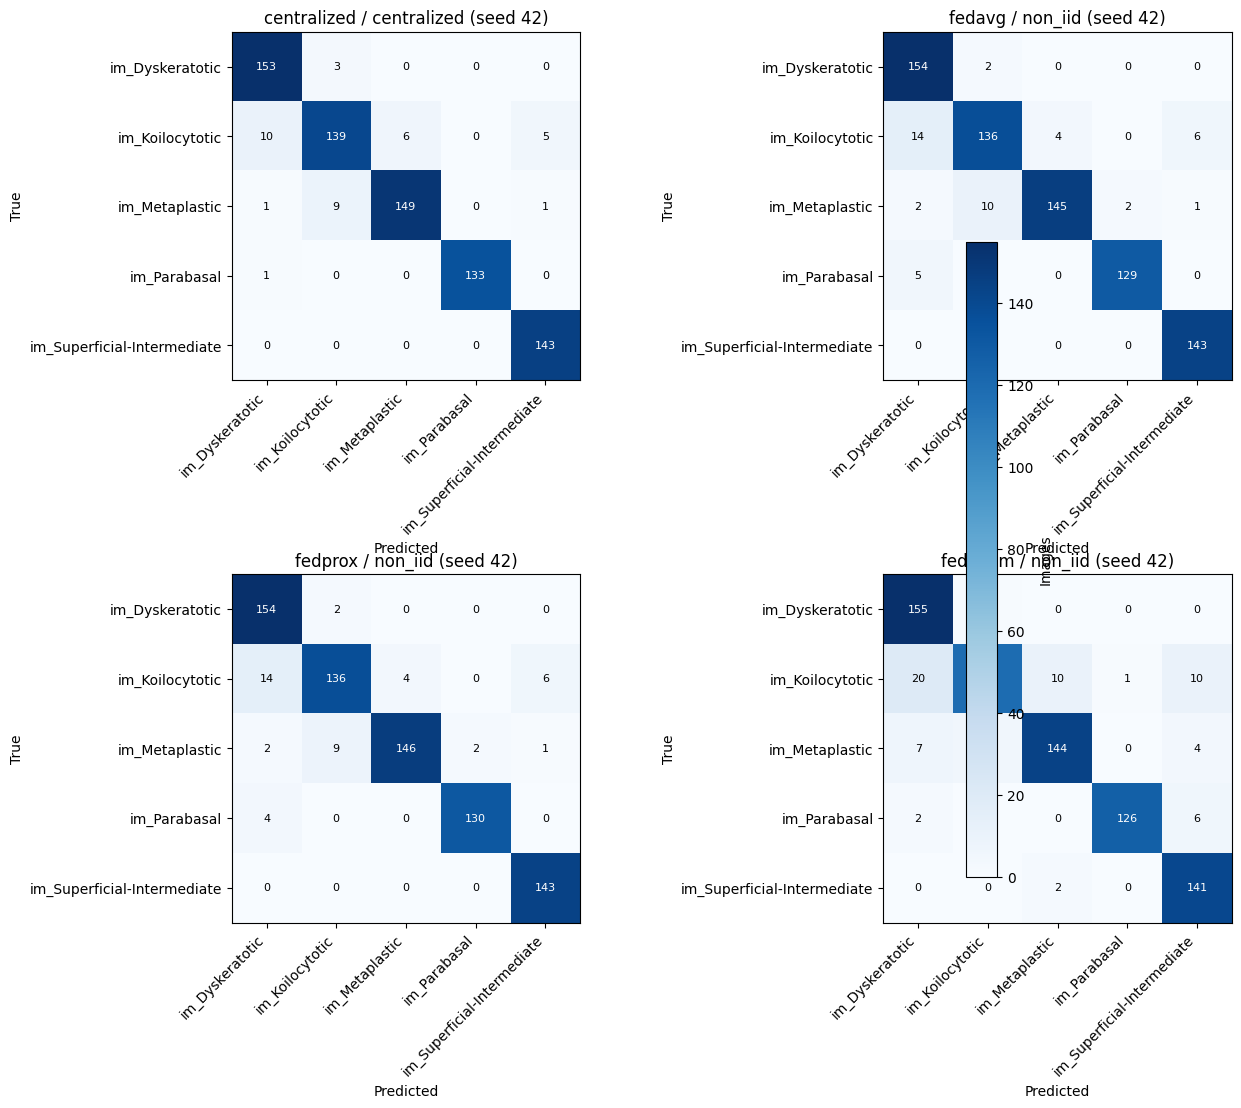

In [10]:
display(per_class_df.groupby(["method","distribution","class"],as_index=False).agg(
    precision=("precision","mean"),recall=("recall","mean"),f1=("f1","mean"),support=("support","mean")))
first_seed=RUN_SEEDS[0]
configs=[("centralized","centralized"),("fedavg","non_iid"),("fedprox","non_iid"),("fedadam","non_iid")]
fig,axes=plt.subplots(2,2,figsize=(13,11))
for ax,(method,dist) in zip(axes.flat,configs):
    yt,yp=confusion_artifacts[(first_seed,method,dist)]; cm=confusion_matrix(yt,yp,labels=list(range(NUM_CLASSES)))
    im=ax.imshow(cm,cmap="Blues"); ax.set_title(f"{method} / {dist} (seed {first_seed})")
    ax.set_xticks(range(NUM_CLASSES),CLASS_NAMES,rotation=45,ha="right"); ax.set_yticks(range(NUM_CLASSES),CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES): ax.text(j,i,str(cm[i,j]),ha="center",va="center",fontsize=8,color="white" if cm[i,j]>cm.max()*.55 else "black")
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.75,label="Images"); fig.tight_layout()
fig.savefig(OUTPUT_DIR/"confusion_matrices_non_iid.png",dpi=160,bbox_inches="tight"); plt.show()


## 10. Runtime and communication estimate

Communication is estimated as full float32 trainable model parameters sent and received by each client once per round, without compression. This is a theoretical payload estimate—not measured network traffic, and not a privacy guarantee.


In [11]:
temp_model=build_model(False)
PARAMETER_BYTES=sum(p.numel()*p.element_size() for p in temp_model.parameters()); del temp_model
cost_rows=[]
for row in run_records:
    rounds=0 if row["method"]=="centralized" else NUM_ROUNDS
    up=PARAMETER_BYTES*NUM_CLIENTS*rounds; down=up
    cost_rows.append({"seed":row["seed"],"method":row["method"],"distribution":row["distribution"],
                      "runtime_seconds":row["runtime_seconds"],"rounds":rounds,
                      "approx_uplink_MB":up/1024**2,"approx_downlink_MB":down/1024**2,
                      "approx_total_MB":(up+down)/1024**2})
cost_df=pd.DataFrame(cost_rows); cost_df.to_csv(OUTPUT_DIR/"runtime_communication_estimates.csv",index=False); display(cost_df)
print("\nSaved outputs:")
for p in sorted(OUTPUT_DIR.iterdir()): print(" -",p.name)


,seed,method,distribution,runtime_seconds,rounds,approx_uplink_MB,approx_downlink_MB,approx_total_MB
0,42,centralized,centralized,556.643091,0,0.000000,0.000000,0.000000
1,42,fedavg,iid,267.608737,10,174.291344,174.291344,348.582687
2,42,fedprox,iid,267.896448,10,174.291344,174.291344,348.582687
3,42,fedadam,iid,271.342998,10,174.291344,174.291344,348.582687
4,42,fedavg,non_iid,265.080419,10,174.291344,174.291344,348.582687
5,42,fedprox,non_iid,269.051936,10,174.291344,174.291344,348.582687
6,42,fedadam,non_iid,278.148613,10,174.291344,174.291344,348.582687
7,123,centralized,centralized,268.388886,0,0.000000,0.000000,0.000000
8,123,fedavg,iid,271.715401,10,174.291344,174.291344,348.582687
9,123,fedprox,iid,270.502830,10,174.291344,174.291344,348.582687



Saved outputs:
 - central_seed123.pt
 - central_seed2025.pt
 - central_seed42.pt
 - confusion_matrices_non_iid.png
 - fedadam_iid_seed123.pt
 - fedadam_iid_seed2025.pt
 - fedadam_iid_seed42.pt
 - fedadam_non_iid_seed123.pt
 - fedadam_non_iid_seed2025.pt
 - fedadam_non_iid_seed42.pt
 - fedavg_iid_seed123.pt
 - fedavg_iid_seed2025.pt
 - fedavg_iid_seed42.pt
 - fedavg_non_iid_seed123.pt
 - fedavg_non_iid_seed2025.pt
 - fedavg_non_iid_seed42.pt
 - fedprox_iid_seed123.pt
 - fedprox_iid_seed2025.pt
 - fedprox_iid_seed42.pt
 - fedprox_non_iid_seed123.pt
 - fedprox_non_iid_seed2025.pt
 - fedprox_non_iid_seed42.pt
 - per_class_metrics_by_seed.csv
 - run_metadata.csv
 - runtime_communication_estimates.csv
 - test_macro_f1_comparison.png
 - test_metrics_by_seed.csv
 - test_metrics_summary.csv
 - validation_history.csv
 - validation_macro_f1_curves.png


In [12]:
!zip -r federated_results.zip /kaggle/working/federated_mobilenet_results

  adding: kaggle/working/federated_mobilenet_results/ (stored 0%)
  adding: kaggle/working/federated_mobilenet_results/fedavg_non_iid_seed2025.pt (deflated 8%)
  adding: kaggle/working/federated_mobilenet_results/test_metrics_summary.csv (deflated 51%)
  adding: kaggle/working/federated_mobilenet_results/run_metadata.csv (deflated 75%)
  adding: kaggle/working/federated_mobilenet_results/fedprox_non_iid_seed123.pt (deflated 8%)
  adding: kaggle/working/federated_mobilenet_results/central_seed123.pt (deflated 8%)
  adding: kaggle/working/federated_mobilenet_results/fedadam_non_iid_seed42.pt (deflated 8%)
  adding: kaggle/working/federated_mobilenet_results/fedprox_iid_seed42.pt (deflated 8%)
  adding: kaggle/working/federated_mobilenet_results/test_macro_f1_comparison.png (deflated 26%)
  adding: kaggle/working/federated_mobilenet_results/fedadam_non_iid_seed2025.pt (deflated 8%)
  adding: kaggle/working/federated_mobilenet_results/fedavg_iid_seed2025.pt (deflated 8%)
  adding: kaggle/w

## 11. Report interpretation and limitations

Use the actual outputs to answer these questions; do not assume an algorithm must win:

1. Does non-IID data lower FedAvg performance or make training less stable?
2. Do FedProx or FedAdam improve non-IID test macro-F1? Is the difference larger than seed-to-seed variation?
3. Which classes account for errors, according to recall and the confusion matrices?
4. How do runtime and estimated communication compare?
5. How does centralized training compare, and what might explain the differences?

State these limitations: clients are simulated in one process; there is no secure aggregation or differential privacy; image-level splits may not control patient/slide overlap; only one public dataset is used; and results do not establish clinical validity. The model predicts dataset cell-image classes, not patient diagnoses.

Artifacts (checkpoints, CSV metrics, histories, and plots) are written to `federated_mobilenet_results/`.
